# Notebook 5: Forecasting models

**Input:** `data/features.csv` (made by Notebook 4)
**Outputs:**
- `data/predictions.csv`: every test-period forecast from every model, used by the simulation (Notebook 6) and the dashboard
- `data/model_results.csv`: all evaluation scores (for the report)
- `models/`: the chosen model for each crop and horizon, saved for the dashboard

**Research question RQ3:** can simple machine-learning models forecast the price change a few weeks ahead better
than the forecasts a farmer could make without them?

**Plan**
1. Baselines: three forecasts that need no machine learning
2. Models: Ridge regression, random forest, gradient boosting
3. Model selection by **time-series cross-validation inside the training period** (the test period is not touched)
4. Final test on the 30% test period (Nov 2019 to 2026), **observed prices only**
5. Is the improvement statistically real? (Wilcoxon test on weekly errors)
6. Does the forecast help the decision? (direction, and "store or sell" signals)
7. Where does it go wrong? (errors by year and season; prediction intervals)
8. Why a random 70/30 split would have fooled us
9. Robustness: with and without PCA, outlier treatment, filled values
10. Which features matter
11. Save

Onion and maize get **separate models**, because Notebooks 3 and 4 showed they behave very differently.

In [1]:
import os
import time
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.base import clone

FEATURES_FILE = "../data/features.csv"
SEED = 42
HORIZONS = [4, 8, 12]
MAIN_H = 12

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_COLOR = {"Maize": BLUE, "Onion": ORANGE}
CROPS = ["Onion", "Maize"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 170)
warnings.filterwarnings("ignore", category=UserWarning)

df = pd.read_csv(FEATURES_FILE, parse_dates=["week"])
df["was_imputed"] = df["was_imputed"].astype(float)

NUM = ["woy_sin", "woy_cos", "week_of_year", "month",
       "chg_1w", "chg_4w", "chg_12w", "chg_26w", "chg_52w",
       "vs_52w_mean", "vs_seasonal_norm", "range_pos_52w",
       "seas_exp_4w_crop", "seas_exp_8w_crop", "seas_exp_12w_crop",
       "seas_exp_4w_mkt", "seas_exp_8w_mkt", "seas_exp_12w_mkt", "room_to_rise_12w",
       "vol_8w", "vol_26w", "premium", "premium_52w", "state_chg_4w",
       "imputed_share_8w", "was_imputed", "pc1", "pc2", "pc3"]
CAT = ["division", "market"]
PCA_FEATURES = ["pc1", "pc2", "pc3"]
print(f"Rows: {len(df):,} | numeric features: {len(NUM)} | categorical: {CAT}")
print(df.groupby(["commodity", "split"]).size().unstack())

Rows: 46,774 | numeric features: 29 | categorical: ['division', 'market']
split      gap (purged)  test  train
commodity                           
Maize               552  9956  22707
Onion               204  5082   8273


### The building blocks

**Preprocessing pipeline.** Missing feature values (mostly in each market's first years, Notebook 4) are filled with
the **training median**, and an indicator column records that a value was missing. Numeric features are standardised
and `division` and `market` are one-hot encoded. All of this sits **inside** a scikit-learn `Pipeline`, so every
statistic (medians, means, standard deviations, categories) is learned from the rows the model is trained on, never
from the rows it is tested on.

**Metrics.** The target is a log price change, so:
- **MAE** (mean absolute error of the log change): 0.10 means forecasts were off by about 10% on average.
- **RMSE**: like MAE but punishes big misses more.
- **MAPE of the future price**: how far the forecast price was from the actual price, in %.
- **Skill vs no-change** = 1 − MAE(model) / MAE(no-change forecast). Above 0 means the model beats simply assuming
  prices stay where they are.
- **R²** on the test period. It can be negative if a model is worse than always predicting the test-period average.
- **Direction accuracy**: how often the forecast got the sign right (rise or fall).

Metrics are computed only on rows whose target was **actually observed** at both ends (not filled in Notebook 2).

In [2]:
def make_preprocessor(num_cols):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])

def make_model(name, params, num_cols=NUM, reduce_dim=False):
    if name == "Ridge":
        est = Ridge(**params)
    elif name == "Random forest":
        est = RandomForestRegressor(n_estimators=200, max_samples=0.5, n_jobs=-1, random_state=SEED, **params)
    elif name == "Gradient boosting":
        est = HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, random_state=SEED, **params)
    steps = [("prep", make_preprocessor(num_cols))]
    if reduce_dim:
        steps.append(("pca", PCA(n_components=0.95, random_state=SEED)))
    steps.append(("model", est))
    return Pipeline(steps)

def metrics(y, pred, y_naive_mae=None):
    y, pred = np.asarray(y), np.asarray(pred)
    err = pred - y
    out = {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
           "MAPE price %": 100 * np.mean(np.abs(np.expm1(err))),
           "R2": 1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2),
           "direction %": 100 * np.mean(np.sign(pred[y != 0]) == np.sign(y[y != 0]))}
    if y_naive_mae is not None:
        out["skill vs no-change %"] = 100 * (1 - out["MAE"] / y_naive_mae)
    return out

def rows(crop, h, split, observed_only=True):
    d = df[(df["commodity"] == crop) & (df["split"] == split) & df[f"target_{h}w"].notna()]
    if observed_only:
        d = d[d[f"target_{h}w_observed"]]
    return d

## 1. Baselines

A model is only worth using if it beats what a farmer could do without it:

| Baseline | Forecast of the change over the next h weeks | What it represents |
| --- | --- | --- |
| **No change** | 0 | "Prices will stay where they are" (a random walk) |
| **Same weeks last year** | the change over the same weeks one year earlier, in this market | "This year will be like last year" |
| **Seasonal average** | the typical change from this week of the year, training years (feature `seas_exp_hw_mkt`) | Long experience of the season |

In [3]:
# "Same weeks last year" needs the price 52 weeks ago and (52 - h) weeks ago, on a complete weekly grid
grid = df.pivot_table(index="week", columns=["commodity", "market"], values="log_price")
full_weeks = pd.date_range(grid.index.min(), grid.index.max(), freq="7D")
grid = grid.reindex(full_weeks)
for h in HORIZONS:
    last_year = (grid.shift(52 - h) - grid.shift(52)).stack(["commodity", "market"], future_stack=True).rename(f"base_lastyear_{h}w")
    last_year.index.names = ["week", "commodity", "market"]
    df = df.drop(columns=[f"base_lastyear_{h}w"], errors="ignore").join(last_year, on=["week", "commodity", "market"])
    df[f"base_nochange_{h}w"] = 0.0
    df[f"base_seasonal_{h}w"] = df[f"seas_exp_{h}w_mkt"]

BASELINES = {"No change": "base_nochange", "Same weeks last year": "base_lastyear", "Seasonal average": "base_seasonal"}
print("Share of test rows where the last-year baseline is available:",
      {c: f"{100 * df.loc[(df['commodity'] == c) & (df['split'] == 'test'), 'base_lastyear_12w'].notna().mean():.0f}%" for c in CROPS})

Share of test rows where the last-year baseline is available: {'Onion': '88%', 'Maize': '79%'}


## 2. Model selection by time-series cross-validation (training period only)

Hyperparameters are chosen **without looking at the test period**. The training period is cut into blocks of time; each
model is trained on the earlier blocks and validated on the next one (an *expanding window*), with a 12-week gap so
that training targets never reach into the validation block.

```
fold 1:  [train............]  gap  [valid]
fold 2:  [train.....................]  gap  [valid]
fold 3:  [train..............................]  gap  [valid]
fold 4:  [train.......................................]  gap  [valid]
```

**A subtle leak, and how it is avoided.** The seasonal-expectation features (`seas_exp_...`) were learned in
Notebook 4 from **all** training years. Inside cross-validation, that would include the validation block itself, so the
features (and the seasonal-average baseline) would already contain the answer for the validation weeks. So in every
fold the seasonal features are **recomputed from the fold's own training rows only**, with exactly the method of
Notebook 4. The first cell below checks that this function reproduces Notebook 4's values when given the full
training period. (The PCA scores are left as computed in Notebook 4: they describe how markets move together in the
same week, not what happens next, so they cannot reveal a validation target.)

Small grids are used so that the notebook runs in a few minutes on a laptop. Selection is done on the main
12-week horizon; the chosen settings are reused for 4 and 8 weeks.

In [4]:
def circular_smooth(s, window=5):
    # moving average over week of year, wrapping week 52 round to week 1 (same as Notebook 4)
    s = s.reindex(range(1, 53))
    padded = pd.concat([s.iloc[-window:], s, s.iloc[:window]])
    return padded.rolling(window, center=True, min_periods=1).mean().iloc[window:-window]

def add_seasonal(fit_rows, apply_rows):
    # learn the seasonal expectation from fit_rows only, and write it into apply_rows
    out = apply_rows.copy()
    for h in HORIZONS:
        ok = fit_rows[fit_rows[f"target_{h}w_observed"]]
        crop_curve = circular_smooth(ok.groupby("week_of_year")[f"target_{h}w"].median())
        out[f"seas_exp_{h}w_crop"] = out["week_of_year"].map(crop_curve).to_numpy()
        st = ok.groupby(["market", "week_of_year"])[f"target_{h}w"].agg(["median", "size"])
        med = st["median"].where(st["size"] >= 5)
        curves = {m: circular_smooth(med.loc[m]) for m in med.index.get_level_values(0).unique()}
        mk = [curves[m].get(w, np.nan) if m in curves else np.nan for m, w in zip(out["market"], out["week_of_year"])]
        out[f"seas_exp_{h}w_mkt"] = pd.Series(mk, index=out.index).fillna(out[f"seas_exp_{h}w_crop"])
        out[f"base_seasonal_{h}w"] = out[f"seas_exp_{h}w_mkt"]
    out["room_to_rise_12w"] = out["seas_exp_12w_mkt"] - out["vs_seasonal_norm"]
    return out

# Check: given the full training period, the function must reproduce Notebook 4's features
for crop in CROPS:
    d = df[df["commodity"] == crop]
    again = add_seasonal(d[d["split"] == "train"], d)
    diff = max(np.nanmax(np.abs(again[c] - d[c])) for c in ["seas_exp_4w_mkt", "seas_exp_12w_mkt", "seas_exp_12w_crop", "room_to_rise_12w"])
    print(f"{crop}: largest difference from Notebook 4's seasonal features = {diff:.1e}")

GRIDS = {
    "Ridge": [{"alpha": a} for a in [0.1, 1, 10, 100]],
    "Random forest": [{"min_samples_leaf": 10, "max_features": 0.33}, {"min_samples_leaf": 30, "max_features": 0.5}],
    "Gradient boosting": [{"learning_rate": 0.05, "max_leaf_nodes": 15, "min_samples_leaf": 50},
                          {"learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 100},
                          {"learning_rate": 0.1, "max_leaf_nodes": 7, "min_samples_leaf": 50}],
}

def time_folds(weeks, n_folds=4, gap=MAIN_H):
    # expanding-window folds over the sorted unique training weeks
    uw = np.sort(weeks.unique())
    edges = np.linspace(0, len(uw), n_folds + 2).astype(int)
    for k in range(1, n_folds + 1):
        val_start, val_end = uw[edges[k]], uw[min(edges[k + 1], len(uw) - 1)]
        train_mask = weeks < val_start - pd.Timedelta(weeks=gap)
        val_mask = (weeks >= val_start) & (weeks < val_end)
        yield train_mask.to_numpy(), val_mask.to_numpy(), val_start

def cv_folds(crop, h):
    # the folds for one crop and horizon, with seasonal features recomputed inside each fold
    tr = rows(crop, h, "train", observed_only=False)
    all_train = df[(df["commodity"] == crop) & (df["split"] == "train")]
    folds = []
    for tr_mask, va_mask, val_start in time_folds(tr["week"]):
        fit_rows = all_train[all_train["week"] + pd.Timedelta(weeks=MAIN_H) < val_start]
        fold_train = add_seasonal(fit_rows, tr[tr_mask])
        fold_val = add_seasonal(fit_rows, tr[va_mask & tr[f"target_{h}w_observed"].to_numpy()])
        folds.append((fold_train, fold_val))
    return folds

cv_rows = []
start = time.time()
target = f"target_{MAIN_H}w"
for crop in CROPS:
    folds = cv_folds(crop, MAIN_H)
    for name, grid_list in GRIDS.items():
        for params in grid_list:
            maes = []
            for fold_train, fold_val in folds:
                model = make_model(name, params).fit(fold_train[NUM + CAT], fold_train[target])
                maes.append(np.mean(np.abs(model.predict(fold_val[NUM + CAT]) - fold_val[target])))
            cv_rows.append({"crop": crop, "model": name, "params": str(params), "CV MAE": np.mean(maes), "CV MAE SD": np.std(maes)})
    # baselines on the same validation folds, for reference
    for bname, col in BASELINES.items():
        maes = []
        for fold_train, fold_val in folds:
            v = fold_val[fold_val[f"{col}_{MAIN_H}w"].notna()]
            maes.append(np.mean(np.abs(v[f"{col}_{MAIN_H}w"] - v[target])))
        cv_rows.append({"crop": crop, "model": bname, "params": "-", "CV MAE": np.mean(maes), "CV MAE SD": np.std(maes)})
cv = pd.DataFrame(cv_rows)
print(f"Cross-validation took {time.time() - start:.0f} seconds")

best_params = (cv[cv["params"] != "-"].sort_values("CV MAE").groupby(["crop", "model"]).first()["params"]
               .map(eval).to_dict())
best_model_name = {crop: cv[(cv["crop"] == crop) & (cv["params"] != "-")].sort_values("CV MAE").iloc[0]["model"] for crop in CROPS}
print("Chosen model for each crop (lowest cross-validation MAE):", best_model_name)
cv.sort_values(["crop", "CV MAE"]).round(4)

Onion: largest difference from Notebook 4's seasonal features = 8.9e-16
Maize: largest difference from Notebook 4's seasonal features = 2.2e-16
Cross-validation took 117 seconds
Chosen model for each crop (lowest cross-validation MAE): {'Onion': 'Random forest', 'Maize': 'Ridge'}


,crop,model,params,CV MAE,CV MAE SD
23,Maize,Seasonal average,-,0.0987,0.0134
21,Maize,No change,-,0.1011,0.0121
14,Maize,Ridge,{'alpha': 10},0.1023,0.0230
15,Maize,Ridge,{'alpha': 100},0.1023,0.0223
13,Maize,Ridge,{'alpha': 1},0.1026,0.0233
12,Maize,Ridge,{'alpha': 0.1},0.1027,0.0234
18,Maize,Gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, ...",0.1084,0.0281
16,Maize,Random forest,"{'min_samples_leaf': 10, 'max_features': 0.33}",0.1085,0.0271
19,Maize,Gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 31, ...",0.1085,0.0272
17,Maize,Random forest,"{'min_samples_leaf': 30, 'max_features': 0.5}",0.1089,0.0268


**Reading the cross-validation.** Inside the calmer training years (validation blocks from about 2012 to 2019),
the gains from machine learning are small: for onion the random forest is only slightly better than the
no-change and seasonal baselines, and for maize no model beats the seasonal average. The chosen models are
**random forest for onion** and **Ridge for maize**. This is an honest warning before looking at the test period:
any advantage should not be expected in every kind of year.

## 3. Final test: train on all training rows, test on the 30% test period

Each model is refitted on the whole training period with its chosen settings, then scored once on the test period.

In [5]:
fitted = {}
test_pred = {}
result_rows = []
start = time.time()
for crop in CROPS:
    for h in HORIZONS:
        tr = rows(crop, h, "train", observed_only=False)
        te = rows(crop, h, "test")
        y_te = te[f"target_{h}w"]
        naive_mae = np.mean(np.abs(y_te))
        for bname, col in BASELINES.items():
            ok = te[f"{col}_{h}w"].notna()
            m = metrics(y_te[ok], te.loc[ok, f"{col}_{h}w"], naive_mae if ok.all() else np.mean(np.abs(y_te[ok])))
            result_rows.append({"crop": crop, "horizon": h, "model": bname, "kind": "baseline", "test rows": int(ok.sum()), **m})
        for name in GRIDS:
            model = make_model(name, best_params[(crop, name)]).fit(tr[NUM + CAT], tr[f"target_{h}w"])
            fitted[(crop, h, name)] = model
            pred = model.predict(te[NUM + CAT])
            test_pred[(crop, h, name)] = pd.Series(pred, index=te.index)
            result_rows.append({"crop": crop, "horizon": h, "model": name, "kind": "machine learning",
                                "test rows": len(te), **metrics(y_te, pred, naive_mae)})
results = pd.DataFrame(result_rows)
print(f"Final training took {time.time() - start:.0f} seconds")
show = results[results["horizon"] == MAIN_H].drop(columns=["horizon"]).round(3)
show.sort_values(["crop", "MAE"])

Final training took 59 seconds


,crop,model,kind,test rows,MAE,RMSE,MAPE price %,R2,direction %,skill vs no-change %
33,Maize,Ridge,machine learning,5410,0.094,0.125,9.728,0.312,70.100,15.399
35,Maize,Gradient boosting,machine learning,5410,0.100,0.135,10.528,0.202,66.437,9.339
34,Maize,Random forest,machine learning,5410,0.105,0.142,11.094,0.115,63.099,5.070
30,Maize,No change,baseline,5410,0.111,0.151,11.372,-0.005,0.000,0.000
32,Maize,Seasonal average,baseline,5410,0.112,0.153,11.780,-0.019,59.685,-0.949
31,Maize,Same weeks last year,baseline,4814,0.171,0.226,18.428,-1.288,46.662,-55.486
15,Onion,Ridge,machine learning,3544,0.318,0.400,35.471,0.462,74.254,25.492
16,Onion,Random forest,machine learning,3544,0.322,0.413,35.991,0.424,73.610,24.407
17,Onion,Gradient boosting,machine learning,3544,0.326,0.416,36.141,0.417,73.493,23.618
14,Onion,Seasonal average,baseline,3544,0.364,0.475,43.658,0.239,71.796,14.760


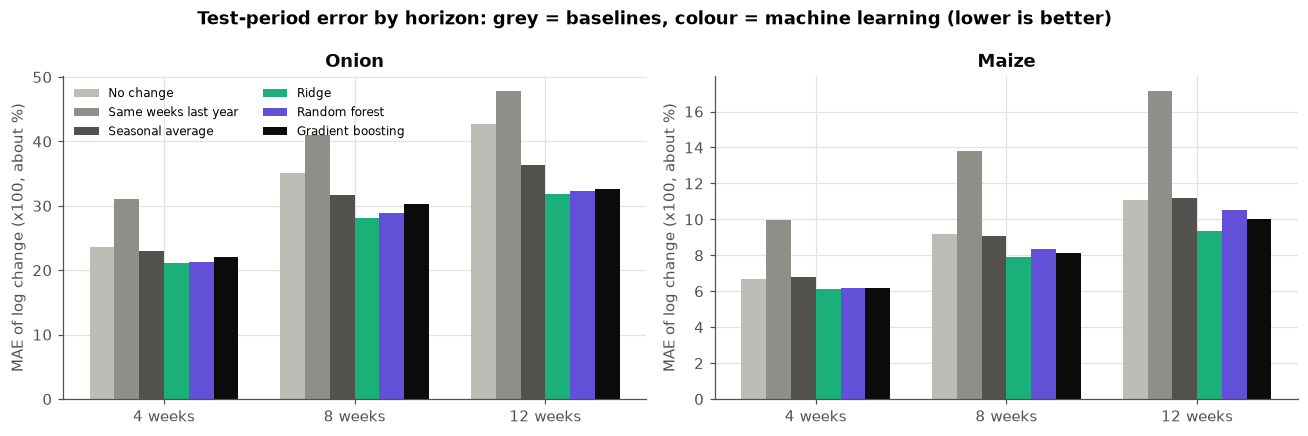

Skill vs the no-change forecast (%):


horizon                    4     8     12
crop  model                              
Maize Gradient boosting   7.7  11.0   9.3
      Random forest       7.7   8.9   5.1
      Ridge               8.4  13.7  15.4
Onion Gradient boosting   6.5  13.8  23.6
      Random forest      10.2  17.5  24.4
      Ridge              10.8  20.1  25.5

Improvement in MAE over the seasonal-average baseline (%):


horizon                    4     8     12
crop  model                              
Maize Gradient boosting   9.4  10.2  10.2
      Random forest       9.4   8.0   6.0
      Ridge              10.1  12.9  16.2
Onion Gradient boosting   3.9   4.4  10.4
      Random forest       7.6   8.5  11.3
      Ridge               8.3  11.4  12.6

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
model_colors = {"No change": "#bdbcb7", "Same weeks last year": "#8f8e89", "Seasonal average": MUTED,
                "Ridge": AQUA, "Random forest": VIOLET, "Gradient boosting": INK}
for ax, crop in zip(axes, CROPS):
    r = results[results["crop"] == crop]
    names = list(model_colors)
    width = 0.13
    for i, name in enumerate(names):
        vals = r[r["model"] == name].set_index("horizon").reindex(HORIZONS)["MAE"]
        ax.bar(np.arange(3) + (i - 2.5) * width, 100 * vals, width=width, color=model_colors[name], label=name)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{h} weeks" for h in HORIZONS])
    ax.set_ylabel("MAE of log change (x100, about %)"); ax.set_title(crop)
axes[0].legend(frameon=False, fontsize=8, ncol=2)
fig.suptitle("Test-period error by horizon: grey = baselines, colour = machine learning (lower is better)", fontweight="bold")
plt.tight_layout(); plt.show()

skill = results[results["kind"] == "machine learning"].pivot_table(index=["crop", "model"], columns="horizon", values="skill vs no-change %").round(1)
seasonal_mae = results[results["model"] == "Seasonal average"].set_index(["crop", "horizon"])["MAE"]
vs_seasonal = results[results["kind"] == "machine learning"].assign(
    **{"improvement vs seasonal %": lambda x: 100 * (1 - x["MAE"] / x.set_index(["crop", "horizon"]).index.map(seasonal_mae))})
print("Skill vs the no-change forecast (%):")
display(skill)
print("Improvement in MAE over the seasonal-average baseline (%):")
vs_seasonal.pivot_table(index=["crop", "model"], columns="horizon", values="improvement vs seasonal %").round(1)

**Reading the results.**
- The **no-change** forecast is a poor guide for onion: prices rarely stay put for 12 weeks. The **seasonal average**
  is much better, and **same weeks last year** is usually the worst, because every year differs (Notebook 3, H5).
- In the test period all three machine-learning models beat all three baselines at every horizon, for both crops.
  At 12 weeks the onion models cut the error of the seasonal average by about 10-13%, and the maize Ridge model by
  about 16%. The gain grows with the horizon.
- The three models are close to each other: with good features, the choice of algorithm matters less than the
  information given to it. Ridge is marginally the best on the onion test set, although the random forest was chosen
  by cross-validation; the difference (0.318 vs 0.322) is far smaller than the year-to-year variation in Section 6.
- The test-period gain is larger than the cross-validation gain. Section 6 shows why.

## 4. Is the improvement statistically real?

The test rows are not independent: in a given week, all markets share the same statewide news. So the comparison is
done on **one value per week**: the average absolute error across markets that week, for the chosen model and for the
best baseline (seasonal average).

- **H0:** the chosen model's weekly error is not lower than the seasonal baseline's.
- **H1:** the chosen model's weekly error is lower.
- **Test:** Wilcoxon signed-rank on the paired weekly errors, one-sided, α = 0.05.

In [7]:
rows_out = []
for crop in CROPS:
    for h in HORIZONS:
        te = rows(crop, h, "test")
        name = best_model_name[crop]
        err = pd.DataFrame({"week": te["week"],
                            "model": np.abs(test_pred[(crop, h, name)] - te[f"target_{h}w"]),
                            "seasonal": np.abs(te[f"base_seasonal_{h}w"] - te[f"target_{h}w"])})
        weekly = err.groupby("week")[["model", "seasonal"]].mean()
        w = stats.wilcoxon(weekly["model"], weekly["seasonal"], alternative="less")
        rows_out.append({"crop": crop, "horizon": h, "model": name, "weeks": len(weekly),
                         "weeks where model was better %": 100 * (weekly["model"] < weekly["seasonal"]).mean(),
                         "mean weekly MAE model": weekly["model"].mean(), "mean weekly MAE seasonal": weekly["seasonal"].mean(),
                         "Wilcoxon W": w.statistic, "p-value": w.pvalue})
significance = pd.DataFrame(rows_out)
significance.round(4)

,crop,horizon,model,weeks,weeks where model was better %,mean weekly MAE model,mean weekly MAE seasonal,Wilcoxon W,p-value
0,Onion,4,Random forest,319,67.3981,0.2083,0.2238,14986.0,0.0000
1,Onion,8,Random forest,311,59.8071,0.2866,0.3092,18179.0,0.0001
2,Onion,12,Random forest,307,57.3290,0.3217,0.3595,17754.0,0.0001
3,Maize,4,Ridge,319,69.5925,0.0590,0.0657,12189.0,0.0000
4,Maize,8,Ridge,311,72.0257,0.0726,0.0830,12269.0,0.0000
5,Maize,12,Ridge,307,69.0554,0.0864,0.0986,13289.0,0.0000


**Interpretation.** A small p-value means the chosen model's weekly errors are lower than the seasonal baseline's
more often, and by more, than chance would explain. The share of weeks in which the model was better shows how
consistent the advantage is: even a clearly better model loses in some weeks.

## 5. Does the forecast help the decision?

A farmer does not need the exact price; they need to know **whether storing will pay**. Two decision-oriented checks
on the 12-week forecast:

1. **Store signal.** The forecast says "store" when the predicted rise exceeds an assumed cost of storing for 12 weeks:
   **10% for onion** (weight loss, rotting and storage) and **3% for maize** (mainly interest on the money tied up).
   These costs are assumptions; Notebook 6 varies them. Then: when the model said "store", how often did the price
   really rise by more than the cost (**precision**), and of all the times storing would have paid, how many did the
   model catch (**recall**)?
2. **Average outcome.** The actual median price change after a "store" signal compared with after a "sell" signal.

In [8]:
STORE_COST = {"Onion": 0.10, "Maize": 0.03}   # assumed total cost of storing for 12 weeks, as a share of the crop's value

dec_rows = []
for crop in CROPS:
    te = rows(crop, MAIN_H, "test")
    y = te[f"target_{MAIN_H}w"]
    worth = y > np.log(1 + STORE_COST[crop])
    forecasts = {"Seasonal average": te[f"base_seasonal_{MAIN_H}w"]}
    forecasts.update({name: test_pred[(crop, MAIN_H, name)] for name in GRIDS})
    for name, f in forecasts.items():
        store = f > np.log(1 + STORE_COST[crop])
        tp, fp, fn = (store & worth).sum(), (store & ~worth).sum(), (~store & worth).sum()
        precision = tp / max(tp + fp, 1); recall = tp / max(tp + fn, 1)
        dec_rows.append({"crop": crop, "forecast": name, "says store %": 100 * store.mean(),
                         "precision %": 100 * precision, "recall %": 100 * recall,
                         "F1": 2 * precision * recall / max(precision + recall, 1e-9),
                         "median change after 'store' %": 100 * np.expm1(y[store].median()) if store.any() else np.nan,
                         "median change after 'sell' %": 100 * np.expm1(y[~store].median()) if (~store).any() else np.nan})
    dec_rows.append({"crop": crop, "forecast": "(storing would have paid)", "says store %": 100 * worth.mean()})
decision = pd.DataFrame(dec_rows)
decision.round(1)

,crop,forecast,says store %,precision %,recall %,F1,median change after 'store' %,median change after 'sell' %
0,Onion,Seasonal average,44.1,61.3,64.9,0.6,25.0,-23.1
1,Onion,Ridge,43.5,66.6,69.4,0.7,31.1,-25.0
2,Onion,Random forest,44.2,63.3,67.3,0.7,28.0,-24.2
3,Onion,Gradient boosting,45.9,63.4,69.9,0.7,26.7,-26.1
4,Onion,(storing would have paid),41.6,NaN,NaN,NaN,NaN,NaN
5,Maize,Seasonal average,60.9,45.1,72.4,0.6,1.7,-3.9
6,Maize,Ridge,46.6,59.8,73.3,0.7,5.7,-5.9
7,Maize,Random forest,53.9,53.4,75.7,0.6,4.2,-4.4
8,Maize,Gradient boosting,51.6,56.5,76.7,0.7,4.9,-5.5
9,Maize,(storing would have paid),38.0,NaN,NaN,NaN,NaN,NaN


**Reading the table.**
- *says store %* is how often each forecast recommended storing; the last row for each crop shows how often storing
  would really have paid.
- A useful forecast has a **big gap between the two median-change columns**: after its "store" signals prices
  should rise well above the cost, and after its "sell" signals they should not.
- These are signals per market-week. Notebook 6 turns them into a full storage simulation with costs, losses and
  uncertainty, and compares the rupees earned with simple rules.

## 6. Where does the model go wrong?

Onion: MAE model vs seasonal, decisions in 2019-2020: 0.481 vs 0.688; 2021 onwards: 0.294 vs 0.305
Maize: MAE model vs seasonal, decisions in 2019-2020: 0.124 vs 0.163; 2021 onwards: 0.082 vs 0.092


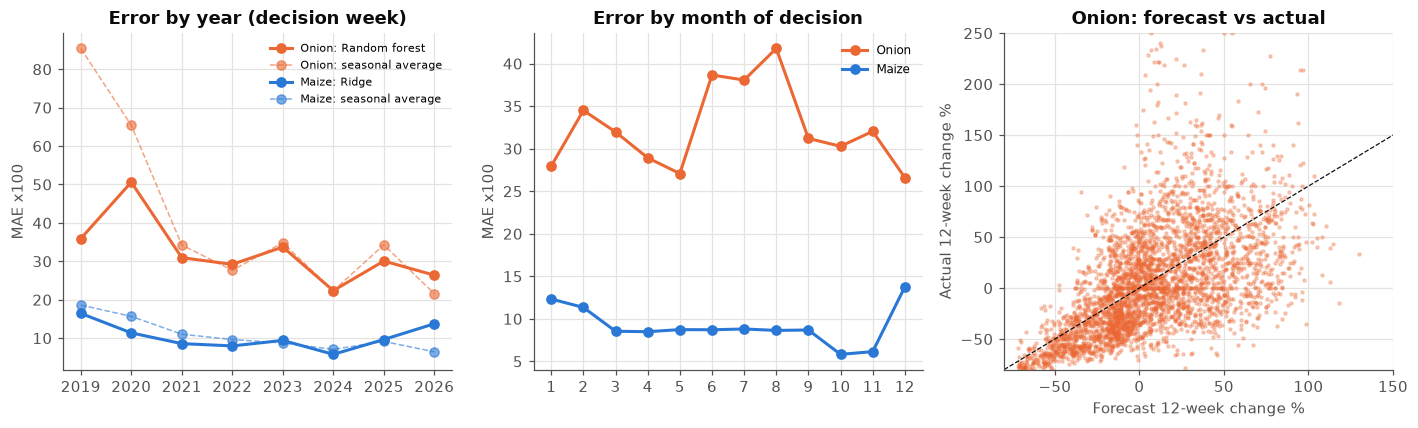

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for crop in CROPS:
    te = rows(crop, MAIN_H, "test")
    name = best_model_name[crop]
    e = pd.DataFrame({"year": te["week"].dt.year, "month": te["week"].dt.month,
                      "model": np.abs(test_pred[(crop, MAIN_H, name)] - te[f"target_{MAIN_H}w"]),
                      "seasonal": np.abs(te[f"base_seasonal_{MAIN_H}w"] - te[f"target_{MAIN_H}w"])})
    by_year = e.groupby("year")[["model", "seasonal"]].mean()
    axes[0].plot(by_year.index, 100 * by_year["model"], color=CROP_COLOR[crop], marker="o", linewidth=2, label=f"{crop}: {name}")
    axes[0].plot(by_year.index, 100 * by_year["seasonal"], color=CROP_COLOR[crop], marker="o", linewidth=1, linestyle="--",
                 alpha=0.6, label=f"{crop}: seasonal average")
    early = e["year"] <= 2020
    print(f"{crop}: MAE model vs seasonal, decisions in 2019-2020: {e.loc[early, 'model'].mean():.3f} vs {e.loc[early, 'seasonal'].mean():.3f}; "
          f"2021 onwards: {e.loc[~early, 'model'].mean():.3f} vs {e.loc[~early, 'seasonal'].mean():.3f}")
    by_month = e.groupby("month")[["model"]].mean()
    axes[1].plot(by_month.index, 100 * by_month["model"], color=CROP_COLOR[crop], marker="o", linewidth=2, label=crop)
axes[0].set_title("Error by year (decision week)"); axes[0].set_ylabel("MAE x100"); axes[0].legend(frameon=False, fontsize=7)
axes[1].set_title("Error by month of decision"); axes[1].set_xticks(range(1, 13)); axes[1].set_ylabel("MAE x100")
axes[1].legend(frameon=False, fontsize=8)

te = rows("Onion", MAIN_H, "test")
pred = test_pred[("Onion", MAIN_H, best_model_name["Onion"])]
axes[2].scatter(100 * np.expm1(pred), 100 * np.expm1(te[f"target_{MAIN_H}w"]), s=4, alpha=0.3, color=ORANGE)
lim = [-80, 250]
axes[2].plot(lim, lim, color=INK, linewidth=0.8, linestyle="--")
axes[2].set_xlim(-80, 150); axes[2].set_ylim(lim)
axes[2].set_xlabel("Forecast 12-week change %"); axes[2].set_ylabel("Actual 12-week change %")
axes[2].set_title("Onion: forecast vs actual")
plt.tight_layout(); plt.show()

**Error patterns.**
- **The model's advantage comes mainly from abnormal years.** In 2019-2020, after the onion crisis peak, the seasonal
  calendar kept expecting rises, while the model saw that prices were far above normal and would fall back (mean
  reversion). For onion decisions in 2019-2020 the model's error was about 30% lower than the seasonal baseline's;
  from 2021 onwards, in more ordinary years, it was only about 4% lower, and in early 2026 the seasonal average was
  slightly better. Maize keeps a steadier advantage (about 24% lower error in 2019-2020, 11% from 2021).
- This explains the cross-validation result: the training years were calmer, so there was less for the model to gain.
  For a farmer it means the forecast matters most **when prices are unusual**, which is exactly when a wrong
  sell-or-store decision costs the most.
- Onion errors are highest for decisions made in June-August, the monsoon months before the kharif harvest, when
  supply is most uncertain.
- The scatter shows the typical behaviour of a forecast under uncertainty: forecasts are **narrower** than reality.
  The model rarely predicts a doubling of price, but such doublings happen. A point forecast alone therefore
  understates risk, so the next cell adds **prediction intervals**.

### Prediction intervals

Gradient-boosting models trained with a **quantile loss** give the 10th and 90th percentiles of the future change. A
well-calibrated 80% interval should contain the actual change about 80% of the time on the test period. Notebook 6
uses these intervals for its Monte Carlo simulation.

In [10]:
quantile_models = {}
cal_rows = []
for crop in CROPS:
    gb_params = best_params[(crop, "Gradient boosting")]
    for h in HORIZONS:
        tr = rows(crop, h, "train", observed_only=False)
        te = rows(crop, h, "test")
        q = {}
        for alpha in [0.1, 0.5, 0.9]:
            m = Pipeline([("prep", make_preprocessor(NUM)),
                          ("model", HistGradientBoostingRegressor(loss="quantile", quantile=alpha, max_iter=300,
                                                                  l2_regularization=1.0, random_state=SEED, **gb_params))])
            m.fit(tr[NUM + CAT], tr[f"target_{h}w"])
            quantile_models[(crop, h, alpha)] = m
            q[alpha] = m.predict(te[NUM + CAT])
        y = te[f"target_{h}w"].to_numpy()
        lo, hi = np.minimum(q[0.1], q[0.9]), np.maximum(q[0.1], q[0.9])
        cal_rows.append({"crop": crop, "horizon": h, "inside 80% interval %": 100 * np.mean((y >= lo) & (y <= hi)),
                         "below 10th pct %": 100 * np.mean(y < lo), "above 90th pct %": 100 * np.mean(y > hi),
                         "median interval width (x100)": 100 * np.median(hi - lo)})
calibration = pd.DataFrame(cal_rows)
calibration.round(1)

,crop,horizon,inside 80% interval %,below 10th pct %,above 90th pct %,median interval width (x100)
0,Onion,4,53.1,25.4,21.6,35.4
1,Onion,8,49.2,30.4,20.4,45.7
2,Onion,12,49.0,32.4,18.5,52.8
3,Maize,4,62.3,21.8,15.9,11.7
4,Maize,8,57.1,26.5,16.4,14.5
5,Maize,12,53.6,31.4,15.0,15.9


**Calibration problem and fix.** The raw quantile intervals are too narrow: they were learned from the calmer
training years. A standard fix is **conformalized quantile regression** (Romano et al., 2019): refit the quantile
models on the earlier training years, measure on the most recent training block (the last cross-validation fold,
before the test period) how far actual values fall outside the interval, and widen every interval by the 80th
percentile of those misses. This uses training data only, so the test period still judges the result fairly.

In [11]:
conf_rows = []
widen = {}
for crop in CROPS:
    gb_params = best_params[(crop, "Gradient boosting")]
    for h in HORIZONS:
        fold_train, fold_val = cv_folds(crop, h)[-1]          # last fold: most recent training block
        qs = {}
        for alpha in [0.1, 0.9]:
            m = Pipeline([("prep", make_preprocessor(NUM)),
                          ("model", HistGradientBoostingRegressor(loss="quantile", quantile=alpha, max_iter=300,
                                                                  l2_regularization=1.0, random_state=SEED, **gb_params))])
            qs[alpha] = m.fit(fold_train[NUM + CAT], fold_train[f"target_{h}w"]).predict(fold_val[NUM + CAT])
        y_val = fold_val[f"target_{h}w"].to_numpy()
        score = np.maximum(qs[0.1] - y_val, y_val - qs[0.9])     # how far outside the interval (negative = inside)
        n = len(score)
        widen[(crop, h)] = np.quantile(score, min(1, np.ceil((n + 1) * 0.8) / n))

        te = rows(crop, h, "test")
        y = te[f"target_{h}w"].to_numpy()
        lo = quantile_models[(crop, h, 0.1)].predict(te[NUM + CAT]) - widen[(crop, h)]
        hi = quantile_models[(crop, h, 0.9)].predict(te[NUM + CAT]) + widen[(crop, h)]
        raw = calibration[(calibration["crop"] == crop) & (calibration["horizon"] == h)].iloc[0]
        conf_rows.append({"crop": crop, "horizon": h, "widened by (x100)": 100 * widen[(crop, h)],
                          "raw coverage %": raw["inside 80% interval %"],
                          "conformal coverage %": 100 * np.mean((y >= lo) & (y <= hi)),
                          "conformal median width (x100)": 100 * np.median(hi - lo)})
conformal = pd.DataFrame(conf_rows)
conformal.round(1)

,crop,horizon,widened by (x100),raw coverage %,conformal coverage %,conformal median width (x100)
0,Onion,4,12.6,53.1,76.7,60.7
1,Onion,8,21.6,49.2,80.1,88.9
2,Onion,12,25.9,49.0,82.5,104.6
3,Maize,4,5.0,62.3,86.7,21.7
4,Maize,8,10.0,57.1,89.9,34.5
5,Maize,12,14.8,53.6,90.5,45.4


**Reading the result.** Conformal widening, using only training data, brings onion coverage close to the 80% target
(about 77-82%). For maize it overshoots (about 87-90%): the intervals are now somewhat too wide, which is the safer
error for a storage decision. The report should state these coverages rather than assume the intervals are perfect.
Notebook 6 uses the conformal intervals.

## 7. Why a random 70/30 split would have fooled us

The same gradient-boosting and Ridge models are now trained on a **random** 70% of all rows and tested on the other
30%. In a random split, the test rows come from the same weeks as the training rows, from neighbouring markets that
moved in exactly the same way. The model is effectively shown the answer.

,crop,model,R2 random split,R2 time split,MAE random split,MAE time split
0,Onion,Ridge,0.476,0.462,0.300,0.318
1,Onion,Gradient boosting,0.813,0.417,0.177,0.326
2,Maize,Ridge,0.449,0.312,0.078,0.094
3,Maize,Gradient boosting,0.641,0.202,0.059,0.100


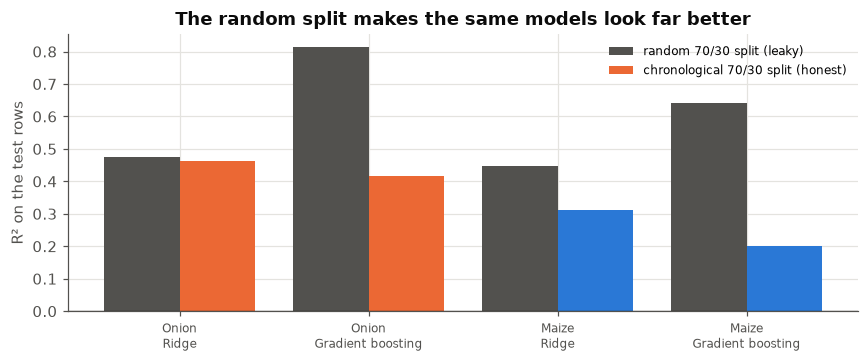

In [12]:
rand_rows = []
for crop in CROPS:
    d = df[(df["commodity"] == crop) & df[f"target_{MAIN_H}w"].notna()]
    rng = np.random.default_rng(SEED)
    is_test = rng.random(len(d)) < 0.30
    tr, te = d[~is_test], d[is_test & d[f"target_{MAIN_H}w_observed"].to_numpy()]
    for name in ["Ridge", "Gradient boosting"]:
        m = make_model(name, best_params[(crop, name)]).fit(tr[NUM + CAT], tr[f"target_{MAIN_H}w"])
        r_random = metrics(te[f"target_{MAIN_H}w"], m.predict(te[NUM + CAT]), np.mean(np.abs(te[f"target_{MAIN_H}w"])))
        r_time = results[(results["crop"] == crop) & (results["horizon"] == MAIN_H) & (results["model"] == name)].iloc[0]
        rand_rows.append({"crop": crop, "model": name,
                          "R2 random split": r_random["R2"], "R2 time split": r_time["R2"],
                          "MAE random split": r_random["MAE"], "MAE time split": r_time["MAE"]})
random_vs_time = pd.DataFrame(rand_rows)
display(random_vs_time.round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
labels = [f"{r.crop}\n{r.model}" for r in random_vs_time.itertuples()]
x = np.arange(len(labels))
ax.bar(x - 0.2, random_vs_time["R2 random split"], width=0.4, color=MUTED, label="random 70/30 split (leaky)")
ax.bar(x + 0.2, random_vs_time["R2 time split"], width=0.4, color=[CROP_COLOR[c] for c in random_vs_time["crop"]],
       label="chronological 70/30 split (honest)")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.axhline(0, color=INK, linewidth=0.8)
ax.set_ylabel("R² on the test rows"); ax.set_title("The random split makes the same models look far better")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Lesson.** Under a random split, gradient boosting appears to explain about 81% of onion price changes; under the
honest time split, about 42%. Ridge barely changes, because a straight-line model cannot memorise what neighbouring
markets did in the same week, while flexible tree models can. So the leak mainly flatters the **flexible** models,
which are exactly the ones a study using a random split would then declare the winner. Nothing about the models
changed, only the way they were tested. This is why the project uses the chronological 70/30 split and reports the
random split only as a warning.

## 8. Robustness checks

Each check changes one thing and retrains the chosen model type and Ridge at the 12-week horizon:

| Check | What changes | Question |
| --- | --- | --- |
| Without PCA features | `pc1`-`pc3` removed | Do the PCA factors from Notebook 4 help? |
| PCA-reduced inputs | all inputs compressed by PCA to the components holding 95% of their variance | Does dimensionality reduction of the inputs help? |
| Observed targets only | training rows with a filled-in target are dropped | Did the gap filling in Notebook 2 help or hurt? |
| Clipped training targets | training targets clipped at their 1st and 99th percentiles | Does taming extreme price moves (outlier treatment) help the model learn? |

In [13]:
check_rows = []
for crop in CROPS:
    tr_all = rows(crop, MAIN_H, "train", observed_only=False)
    te = rows(crop, MAIN_H, "test")
    y_te = te[f"target_{MAIN_H}w"]
    naive = np.mean(np.abs(y_te))
    for name in sorted({"Ridge", best_model_name[crop]}):
        p = best_params[(crop, name)]
        variants = {
            "Main model": (make_model(name, p), tr_all, tr_all[f"target_{MAIN_H}w"]),
            "Without PCA features": (make_model(name, p, num_cols=[c for c in NUM if c not in PCA_FEATURES]),
                                     tr_all, tr_all[f"target_{MAIN_H}w"]),
            "PCA-reduced inputs (95%)": (make_model(name, p, reduce_dim=True), tr_all, tr_all[f"target_{MAIN_H}w"]),
            "Observed targets only": (make_model(name, p), tr_all[tr_all[f"target_{MAIN_H}w_observed"]],
                                      tr_all.loc[tr_all[f"target_{MAIN_H}w_observed"], f"target_{MAIN_H}w"]),
        }
        lo, hi = tr_all[f"target_{MAIN_H}w"].quantile([0.01, 0.99])
        variants["Clipped training targets"] = (make_model(name, p), tr_all, tr_all[f"target_{MAIN_H}w"].clip(lo, hi))
        for vname, (model, X, y) in variants.items():
            model.fit(X[NUM + CAT], y)
            m = metrics(y_te, model.predict(te[NUM + CAT]), naive)
            extra = {}
            if vname == "PCA-reduced inputs (95%)":
                extra["inputs after PCA"] = model.named_steps["pca"].n_components_
            check_rows.append({"crop": crop, "model": name, "variant": vname, "MAE": m["MAE"], "R2": m["R2"],
                               "skill vs no-change %": m["skill vs no-change %"], **extra})
checks = pd.DataFrame(check_rows)
base = checks[checks["variant"] == "Main model"].set_index(["crop", "model"])["MAE"]
checks["MAE change vs main %"] = 100 * (checks["MAE"] / checks.set_index(["crop", "model"]).index.map(base) - 1)
checks.round(3)

,crop,model,variant,MAE,R2,skill vs no-change %,inputs after PCA,MAE change vs main %
0,Onion,Random forest,Main model,0.322,0.424,24.407,NaN,0.000
1,Onion,Random forest,Without PCA features,0.322,0.424,24.496,NaN,-0.119
2,Onion,Random forest,PCA-reduced inputs (95%),0.335,0.366,21.390,27.0,3.991
3,Onion,Random forest,Observed targets only,0.323,0.421,24.176,NaN,0.305
4,Onion,Random forest,Clipped training targets,0.324,0.417,23.941,NaN,0.617
5,Onion,Ridge,Main model,0.318,0.462,25.492,NaN,0.000
6,Onion,Ridge,Without PCA features,0.312,0.476,26.904,NaN,-1.895
7,Onion,Ridge,PCA-reduced inputs (95%),0.323,0.419,24.251,27.0,1.666
8,Onion,Ridge,Observed targets only,0.323,0.443,24.354,NaN,1.528
9,Onion,Ridge,Clipped training targets,0.318,0.458,25.411,NaN,0.109


**Reading the checks.** A negative *MAE change* means the variant is better than the main model; differences of
1-2% are small compared with the year-to-year variation in Section 6.
- **PCA factors as features do not help the forecast.** Removing `pc1`-`pc3` changes the error by less than 2%
  (slightly better for onion Ridge). The statewide movement they capture is already in `state_chg_4w` and `premium`.
- **Compressing all inputs with PCA makes forecasts worse** (by about 2-4% for onion and 10% for maize Ridge). PCA keeps
  the directions with the most *variance in the inputs*, which are not necessarily the directions that predict the
  *target*. Ridge already handles the correlated inputs through its penalty.
- So PCA earns its place in this project as an **analysis tool** (RQ2: how integrated the mandis are, Notebook 4),
  not as a forecasting step. That is a legitimate finding, and the reason the main models use the full feature set.
- **Training on observed targets only** or **clipping extreme training targets** changes the error by under 2%: the
  gap filling and outlier treatment from Notebook 2 did not distort the models.

## 9. Which features matter?

**Permutation importance** on the test period: shuffle one input column at a time and measure how much the MAE gets
worse. A large increase means the model relies on that input. It is measured on the test period, so it shows what
the model actually used when facing new data.

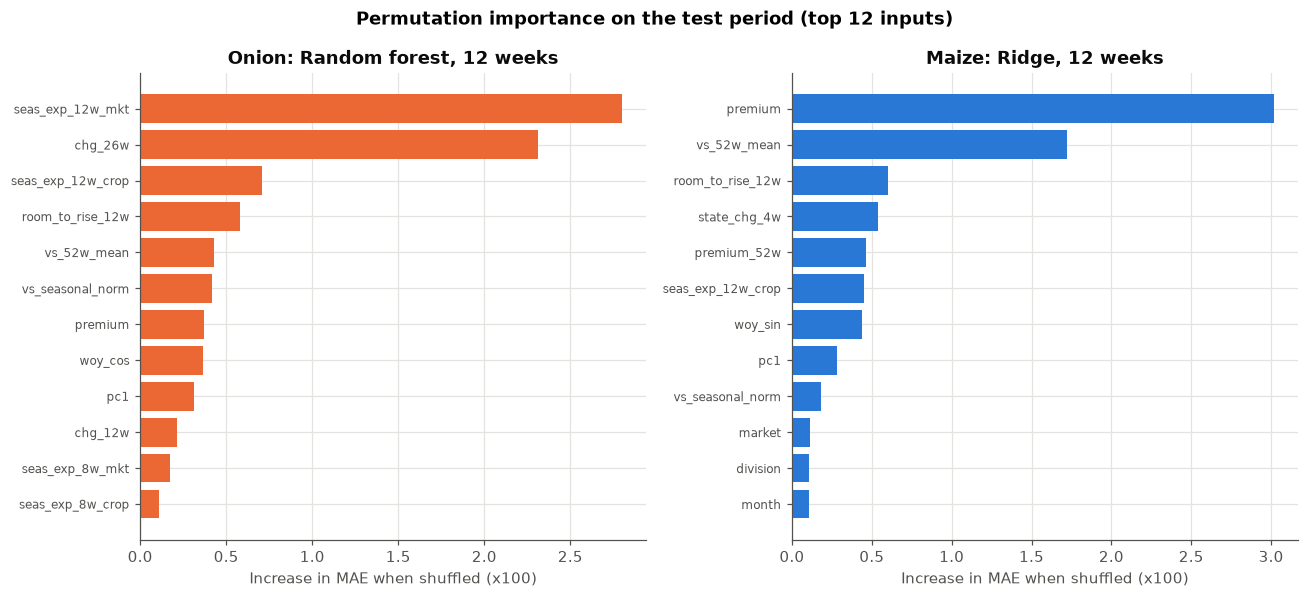

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
importance_tables = {}
for ax, crop in zip(axes, CROPS):
    name = best_model_name[crop]
    te = rows(crop, MAIN_H, "test")
    X_te = te[NUM + CAT]
    pi = permutation_importance(fitted[(crop, MAIN_H, name)], X_te, te[f"target_{MAIN_H}w"],
                                scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
    importance_tables[crop] = imp
    top = imp.tail(12)
    ax.barh(top.index, 100 * top.values, color=CROP_COLOR[crop])
    ax.set_xlabel("Increase in MAE when shuffled (x100)"); ax.set_title(f"{crop}: {name}, 12 weeks")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Permutation importance on the test period (top 12 inputs)", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Onion (random forest):** the market's **seasonal expectation** is by far the most important input, followed by
  the **26-week price change** and the other "price vs normal" features (mean reversion). These are the same two
  signals Notebook 4 found in the exploratory analysis.
- **Maize (Ridge):** the market's **premium** over the statewide price matters most (a market far above the state price
  tends to come back into line), followed by the price compared with its 52-week average. For maize, where the season
  is weak, *where the price stands compared with other markets and with its own past* matters more than the calendar.
- Short-term momentum (1-4 week changes) does not appear in either top list, again matching Notebook 4.
This agreement between the exploratory analysis and the trained models is evidence that the models learned real market
behaviour rather than noise.

## 10. Save predictions, results and models

In [15]:
out = df[df["split"] == "test"].copy()
for crop in CROPS:
    for h in HORIZONS:
        idx = out.index[out["commodity"] == crop]
        X = out.loc[idx, NUM + CAT]
        for name in GRIDS:
            out.loc[idx, f"pred_{h}w_{name.lower().replace(' ', '_')}"] = fitted[(crop, h, name)].predict(X)
        out.loc[idx, f"pred_{h}w_best"] = fitted[(crop, h, best_model_name[crop])].predict(X)
        for alpha in [0.1, 0.5, 0.9]:
            out.loc[idx, f"q{int(alpha * 100)}_{h}w_raw"] = quantile_models[(crop, h, alpha)].predict(X)
        out.loc[idx, f"q10_{h}w"] = out.loc[idx, f"q10_{h}w_raw"] - widen[(crop, h)]   # conformal 80% interval
        out.loc[idx, f"q90_{h}w"] = out.loc[idx, f"q90_{h}w_raw"] + widen[(crop, h)]
        out.loc[idx, f"q50_{h}w"] = out.loc[idx, f"q50_{h}w_raw"]
keep = (["commodity", "market", "district", "division", "week", "price", "price_filled", "log_price"]
        + [c for c in out.columns if c.startswith(("target_", "base_", "pred_", "q10_", "q50_", "q90_"))]
        + ["seas_exp_12w_mkt", "vs_seasonal_norm"])
out[keep].to_csv("../data/predictions.csv", index=False)

results_all = results.merge(significance[["crop", "horizon", "p-value"]].rename(columns={"p-value": "Wilcoxon p vs seasonal (best model)"}),
                            on=["crop", "horizon"], how="left")
results_all.to_csv("../data/model_results.csv", index=False)

os.makedirs("../models", exist_ok=True)
for crop in CROPS:
    for h in HORIZONS:
        joblib.dump(fitted[(crop, h, best_model_name[crop])], f"../models/{crop.lower()}_{h}w_best.joblib")
        for alpha in [0.1, 0.9]:
            joblib.dump(quantile_models[(crop, h, alpha)], f"../models/{crop.lower()}_{h}w_q{int(alpha * 100)}.joblib")
joblib.dump({"numeric": NUM, "categorical": CAT, "best_model": best_model_name, "params": best_params,
             "conformal_widen": widen, "store_cost_assumed": STORE_COST}, "../models/model_info.joblib")

print(f"Saved data/predictions.csv: {len(out):,} test-period market-weeks, {len(keep)} columns")
print(f"Saved data/model_results.csv: {len(results_all)} rows")
print("Saved models:", sorted(os.listdir("../models")))

Saved data/predictions.csv: 15,038 test-period market-weeks, 55 columns
Saved data/model_results.csv: 36 rows
Saved models: ['maize_12w_best.joblib', 'maize_12w_q10.joblib', 'maize_12w_q90.joblib', 'maize_4w_best.joblib', 'maize_4w_q10.joblib', 'maize_4w_q90.joblib', 'maize_8w_best.joblib', 'maize_8w_q10.joblib', 'maize_8w_q90.joblib', 'model_info.joblib', 'onion_12w_best.joblib', 'onion_12w_q10.joblib', 'onion_12w_q90.joblib', 'onion_4w_best.joblib', 'onion_4w_q10.joblib', 'onion_4w_q90.joblib', 'onion_8w_best.joblib', 'onion_8w_q10.joblib', 'onion_8w_q90.joblib']


## 11. Answer to RQ3

| Question | Answer from this notebook |
| --- | --- |
| Do the models beat the baselines? | Yes on the test period: at 12 weeks, about 11-13% lower error than the seasonal average for onion and 16% for maize; all models beat all baselines at all horizons. |
| Is the improvement real? | Yes: lower weekly error in 57-72% of weeks, Wilcoxon p ≤ 0.0001 for every crop and horizon. |
| Is it the same in every year? | No. The gain comes mainly from abnormal years (2019-2020); in ordinary years the model is about as good as the seasonal average, and cross-validation in the calmer training years showed little gain. |
| Does it help the decision? | For onion, prices rose a median of about 28-31% after the models' "store" signals and fell about 24-25% after "sell" signals, a wider gap than the seasonal rule gives. Rupee value: Notebook 6. |
| How should models be tested? | Chronologically. A random split inflated gradient boosting's R² from about 0.42 to 0.81. |
| Did PCA, cleaning and outlier choices matter? | PCA helps understanding (RQ2) but not forecasting; cleaning choices changed errors by under 2%. |
| What did the model learn? | Seasonal expectation, mean reversion (price vs normal, 26-week change) and the market's premium, matching Notebook 4. |

**Limits.** The models forecast from prices alone: there are no arrival quantities, weather or export-policy inputs in
this dataset, so shocks such as the 2019 export ban cannot be foreseen. The test period is a single run of history
(2019-2026); a different period might rank the models differently.

**Next:** Notebook 6 asks the question that matters to a farmer and that accuracy scores cannot answer: **does
following this forecast earn more rupees than simple rules**, after storage costs and losses?